# Sampled-Current, Pulse Voltammetry & Chronopotentiometry

This tutorial covers step-family and pulse techniques alongside galvanostatic chronopotentiometry in [`softpotato.techniques`](../api/techniques.md):

1. **Sampled-Current Voltammetry (SCV)** using `SampledCurrentVoltammetry` and `plot_scv()`.
2. **Differential Pulse Voltammetry (DPV)** using `DifferentialPulseVoltammetry` and `plot_dpv()`.
3. **Square Wave Voltammetry (SWV)** using `SquareWaveVoltammetry` and `plot_swv()`.
4. **Chronopotentiometry (CP)** using `Chronopotentiometry` and `analyze_sand()`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from softpotato.geometry import PlanarGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import (
    Chronopotentiometry,
    DifferentialPulseVoltammetry,
    SampledCurrentVoltammetry,
    SquareWaveVoltammetry,
    analyze_sand,
    plot_dpv,
    plot_scv,
    plot_swv,
    simulate,
)

D = 1e-9       # m^2/s
c_bulk = 1.0   # mol/m^3 (1 mM)
area = 1e-4    # m^2 (1 cm^2)

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=0.0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0, standard_potential=0.0, n_electrons=-1)
geom = PlanarGeometry(area=area)
nernst = NernstianEquilibrium(E0=0.0, n=1)

## 1. Sampled-Current Voltammetry (SCV)

`SampledCurrentVoltammetry` executes a family of independent constant-potential steps across a potential window and samples the current transients $I_k(t)$ at one or more fixed sampling times $\tau$.

Sampled currents shape (n_tau, n_steps): (4, 13)


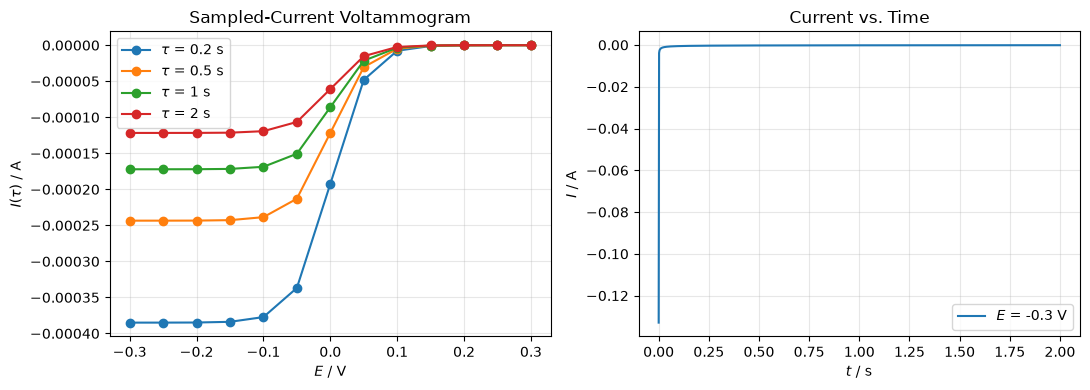

In [2]:
scv = SampledCurrentVoltammetry(
    E_start=0.3,
    E_end=-0.3,
    dE=0.05,
    duration=2.0,
    sample_times=[0.2, 0.5, 1.0, 2.0],
)
res_scv = simulate(scv, [ox, red], geometry=geom, kinetics=nernst)

# Inspect sampled currents at the configured tau values
e_steps, i_sampled = res_scv.sample_currents()
print("Sampled currents shape (n_tau, n_steps):", i_sampled.shape)

# Plot sampled-current voltammograms and an individual step transient
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
plot_scv(res_scv, ax=ax1)
res_scv.plot("i_vs_t", step=-1, ax=ax2)
fig.tight_layout()
plt.show()

## 2. Differential Pulse Voltammetry (DPV) & Square Wave Voltammetry (SWV)

Both `DifferentialPulseVoltammetry` and `SquareWaveVoltammetry` automatically expose sampled component views (`E_base`, `i_pre`, `i_pulse`, `i_diff` for DPV; `E_step`, `i_forward`, `i_reverse`, `i_net` for SWV) and dedicated plotters (`plot_dpv`, `plot_swv`).

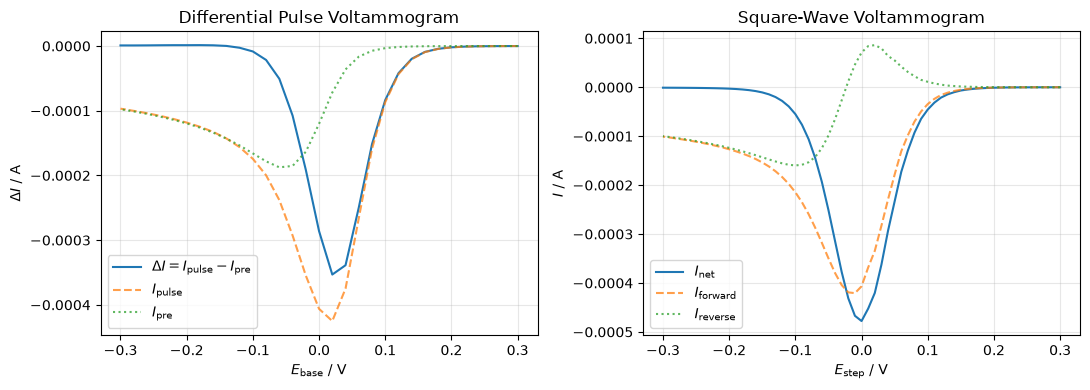

In [3]:
dpv = DifferentialPulseVoltammetry(
    E_start=0.3,
    E_end=-0.3,
    step_height=0.02,
    pulse_amplitude=-0.05,
    pulse_width=0.05,
    pulse_period=0.2,
)
res_dpv = simulate(dpv, [ox, red], geometry=geom, kinetics=nernst)

swv = SquareWaveVoltammetry(
    E_start=0.3,
    E_end=-0.3,
    step_height=0.01,
    amplitude=0.025,
    frequency=10.0,
)
res_swv = simulate(swv, [ox, red], geometry=geom, kinetics=nernst)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
plot_dpv(res_dpv, show_components=True, ax=ax1)
plot_swv(res_swv, show_components=True, ax=ax2)
fig.tight_layout()
plt.show()

## 3. Galvanostatic Chronopotentiometry & Sand Transition Time

In galvanostatic mode, `Chronopotentiometry` applies a constant current $I$, recovers the electrode potential $E(t)$ from surface concentrations, and `analyze_sand()` detects the transition time $\tau$ to estimate diffusivity $D$ via the Sand equation $I \tau^{1/2} = \frac{1}{2} n F A \sqrt{\pi D} c^*$.

Detected transition time tau = 0.0050 s
Estimated D (Sand) = 2.462e-15 m^2/s (true: 1.000e-09 m^2/s)


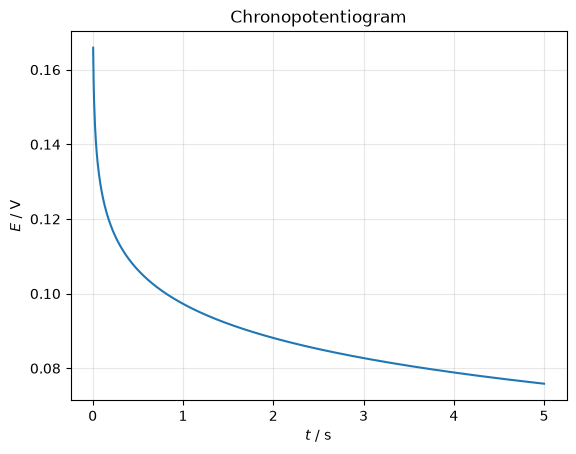

In [4]:
cp = Chronopotentiometry(current=-6e-6, duration=5.0)
res_cp = simulate(cp, [ox, red], geometry=geom, kinetics=nernst)

sand_diag = analyze_sand(res_cp, n=1, area=area, c_bulk=c_bulk)
print(f"Detected transition time tau = {sand_diag.tau:.4f} s")
print(f"Estimated D (Sand) = {sand_diag.D_estimated:.3e} m^2/s (true: {D:.3e} m^2/s)")

fig_cp, ax_cp = res_cp.plot("E_vs_t", show_transition_time=True)
plt.show()